# Climate Statistics and Indices

## Extreme Climate Indices with CDO

Climate indices summarize key aspects of the climate system. This notebook demonstrates how to compute basic statistics and climate extreme indices using CDO operators on real NCEP/DOE Reanalysis-2 temperature and CHIRPS precipitation data.

### Learning Objectives:
- Compute basic statistics (mean, standard deviation, percentiles)
- Calculate frost days and tropical nights
- Compute consecutive dry days (CDD)
- Visualize climate statistics with histograms and time series

In [1]:
import subprocess
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import os
# CDO is installed as cdo.cmd on Windows; use the right executable name.
CDO = 'cdo.cmd' if os.name == 'nt' else 'cdo'


In [2]:
# Use real monthly climate data: reanalysis temperature + CHIRPS precipitation
data_dir = '../data'
output_dir = '../output'
os.makedirs(data_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

tas_file = os.path.join('..', 'datasets', 'tas_sample.nc')
pr_file = os.path.join('..', 'datasets', 'pr_sample.nc')

# Cold-month temperature from a Siberian box (real reanalysis grid points)
ds_tas = xr.open_dataset(tas_file).sel(lat=slice(70, 50), lon=slice(90, 130))
lat_w = xr.DataArray(np.cos(np.deg2rad(ds_tas.lat.values)),
                     dims=('lat',), coords={'lat': ds_tas.lat})
temp_series = ds_tas.tas.weighted(lat_w).mean(dim=('lat', 'lon')) - 273.15

# Real CHIRPS precipitation averaged over Ethiopia
ds_pr = xr.open_dataset(pr_file)
precip_series = ds_pr.pr.mean(dim=('latitude', 'longitude'))

time = ds_tas.time.values
ds = xr.Dataset(
    {
        'temperature': ('time', temp_series.values,
                        {'units': 'degC', 'long_name': 'Monthly mean temperature'}),
        'precipitation': ('time', precip_series.values,
                          {'units': 'mm/month', 'long_name': 'Monthly precipitation'}),
    },
    coords={'time': time}
)
ds.attrs = {'title': 'Real climate indices input',
            'source': 'NCEP/DOE Reanalysis-2 + CHIRPS (real observations)'}

ts_file = os.path.join(data_dir, 'real_climate_indices.nc')
ds.to_netcdf(ts_file)
print(f'Using real datasets: {tas_file}, {pr_file}')
print(f'Period: {time[0]} to {time[-1]} ({len(time)} months)')
print(f'Temperature: {ds.temperature.min().values:.1f} to {ds.temperature.max().values:.1f} degC')
print(f'Precipitation: {ds.precipitation.min().values:.1f} to {ds.precipitation.max().values:.1f} mm/month')

Using real datasets: ..\datasets\tas_sample.nc, ..\datasets\pr_sample.nc
Period: 1980-01-01T00:00:00.000000000 to 2010-12-01T00:00:00.000000000 (372 months)
Temperature: -23.9 to 16.6 degC
Precipitation: 4.2 to 122.2 mm/month


In [3]:
# Compute basic statistics (mean, std, percentiles) with CDO
for stat, op in [('mean', 'timmean'), ('std', 'timstd')]:
    subprocess.run([CDO, op, ts_file, os.path.join(output_dir, f'ts_{stat}.nc')],
                   capture_output=True, text=True)

# timpctl needs explicit histogram bounds from timmin/timmax
min_file = os.path.join(output_dir, 'ts_min.nc')
max_file = os.path.join(output_dir, 'ts_max.nc')
subprocess.run([CDO, 'timmin', ts_file, min_file], capture_output=True, text=True)
subprocess.run([CDO, 'timmax', ts_file, max_file], capture_output=True, text=True)
for pctl in (10, 90):
    subprocess.run([CDO, f'timpctl,{pctl}', ts_file, min_file, max_file,
                    os.path.join(output_dir, f'ts_pctl{pctl}.nc')],
                   capture_output=True, text=True)

ds_mean = xr.open_dataset(os.path.join(output_dir, 'ts_mean.nc'))
ds_std = xr.open_dataset(os.path.join(output_dir, 'ts_std.nc'))
ds_p10 = xr.open_dataset(os.path.join(output_dir, 'ts_pctl10.nc'))
ds_p90 = xr.open_dataset(os.path.join(output_dir, 'ts_pctl90.nc'))

print('Basic Statistics (over full period):')
print('  Temperature:')
print(f'    Mean:       {ds_mean.temperature.values.ravel()[0]:.2f} degC')
print(f'    Std Dev:    {ds_std.temperature.values.ravel()[0]:.2f} degC')
print(f'    10th Pctl:  {ds_p10.temperature.values.ravel()[0]:.2f} degC')
print(f'    90th Pctl:  {ds_p90.temperature.values.ravel()[0]:.2f} degC')
print('  Precipitation:')
print(f'    Mean:       {ds_mean.precipitation.values.ravel()[0]:.2f} mm/month')
print(f'    Std Dev:    {ds_std.precipitation.values.ravel()[0]:.2f} mm/month')
print(f'    10th Pctl:  {ds_p10.precipitation.values.ravel()[0]:.2f} mm/month')
print(f'    90th Pctl:  {ds_p90.precipitation.values.ravel()[0]:.2f} mm/month')

Basic Statistics (over full period):
  Temperature:
    Mean:       -5.12 degC
    Std Dev:    14.28 degC
    10th Pctl:  -22.59 degC
    90th Pctl:  13.63 degC
  Precipitation:
    Mean:       52.34 mm/month
    Std Dev:    35.38 mm/month
    10th Pctl:  6.83 mm/month
    90th Pctl:  103.24 mm/month


In [4]:
# Compute frost days (count months with T < 0 degC)
# Using cdo ecacf (ECA Climate Indices) or custom logic
# eca_fd computes frost days

subprocess.run([CDO, 'eca_fd', ts_file,
               os.path.join(output_dir, 'frost_days.nc')],
              capture_output=True, text=True)

ds_frost = xr.open_dataset(os.path.join(output_dir, 'frost_days.nc'))
print('Frost Months (T < 0 degC):')
print(ds_frost)

# Also compute manually for verification
ds_orig = xr.open_dataset(ts_file)
frost_days_year = (ds_orig.temperature < 0).astype(int).groupby('time.year').sum('time')
print(f'\nMean frost months per year: {frost_days_year.mean().values:.1f}')

Frost Months (T < 0 degC):
<xarray.Dataset> Size: 12B
Dimensions:                           (time: 1)
Coordinates:
  * time                              (time) datetime64[ns] 8B 2010-12-01
Data variables:
    frost_days_index_per_time_period  (time) float32 4B ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Sun Nov 22 18:50:14 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...



Mean frost months per year: 7.0


In [5]:
# Compute tropical nights (count days with T > 20 degC)
# eca_tr counts tropical nights

subprocess.run([CDO, 'eca_tr', ts_file,
               os.path.join(output_dir, 'tropical_nights.nc')],
              capture_output=True, text=True)

ds_tropical = xr.open_dataset(os.path.join(output_dir, 'tropical_nights.nc'))
print('Warm Months (T > 20 degC):')
print(ds_tropical)

# Manual check
tropical_nights_year = (ds_orig.temperature > 20).astype(int).groupby('time.year').sum('time')
print(f'\nMean warm months per year: {tropical_nights_year.mean().values:.1f}')

Warm Months (T > 20 degC):
<xarray.Dataset> Size: 12B
Dimensions:                                (time: 1)
Coordinates:
  * time                                   (time) datetime64[ns] 8B 2010-12-01
Data variables:
    tropical_nights_index_per_time_period  (time) float32 4B ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Sun Nov 22 18:50:15 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...

Mean warm months per year: 0.0


In [6]:
# Compute CDD (Consecutive Dry Months) from real precipitation
# CDD = maximum run of consecutive months with precipitation < 50 mm

def max_consecutive_dry(dry_array):
    max_run = current_run = 0
    for d in dry_array:
        if d:
            current_run += 1
            max_run = max(max_run, current_run)
        else:
            current_run = 0
    return max_run

ds_orig_reload = xr.open_dataset(ts_file)
years = np.unique(ds_orig_reload.time.dt.year.values)
cdd_values = np.array([
    max_consecutive_dry(
        ds_orig_reload.precipitation.sel(
            time=ds_orig_reload.time.dt.year == yr).values < 50.0
    )
    for yr in years
])
yearly_cdd = xr.DataArray(cdd_values, dims=('year',), coords={'year': years})

print('Consecutive Dry Months (CDD) by year:')
for yr, cdd in zip(yearly_cdd.year.values, yearly_cdd.values):
    print(f'  {yr}: {cdd} months')
print(f'\nMean CDD: {yearly_cdd.mean().values:.1f} months')
print(f'Max CDD:  {yearly_cdd.max().values} months')

Consecutive Dry Months (CDD) by year:
  1980: 3 months
  1981: 3 months
  1982: 3 months
  1983: 3 months
  1984: 3 months
  1985: 3 months
  1986: 3 months
  1987: 3 months
  1988: 3 months
  1989: 3 months
  1990: 3 months
  1991: 3 months
  1992: 4 months
  1993: 3 months
  1994: 4 months
  1995: 3 months
  1996: 3 months
  1997: 4 months
  1998: 3 months
  1999: 3 months
  2000: 3 months
  2001: 3 months
  2002: 3 months
  2003: 3 months
  2004: 3 months
  2005: 3 months
  2006: 4 months
  2007: 3 months
  2008: 3 months
  2009: 3 months
  2010: 3 months

Mean CDD: 3.1 months
Max CDD:  4 months


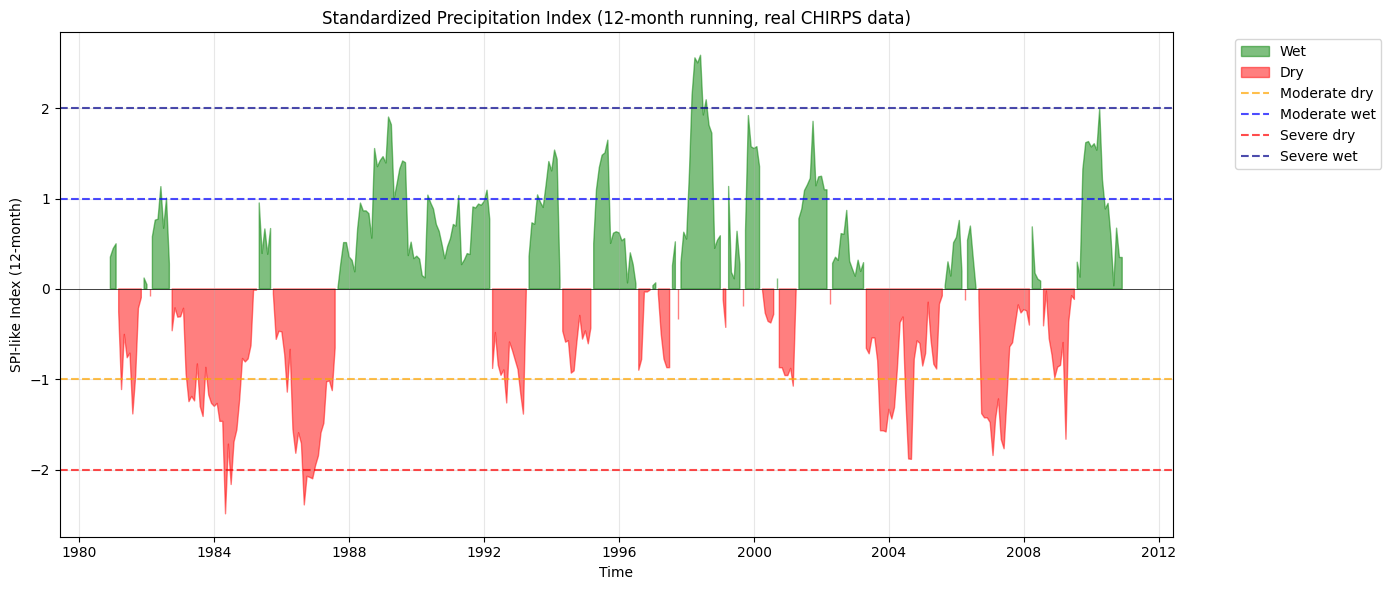

In [7]:
# Compute SPI-like indices (Standardized Precipitation Index)
# SPI is based on a gamma distribution fit to precipitation
# Simple approximation using standardized anomalies

precip = xr.open_dataset(ts_file).precipitation.values

# Compute running 12-month precipitation totals
window = 12
running_precip = np.convolve(precip, np.ones(window)/window, mode='valid')

# Standardize (z-score)
spi_like = (running_precip - running_precip.mean()) / running_precip.std()

# Trim to match time axis
spi_time = time[window-1:]

plt.figure(figsize=(14, 6))
plt.fill_between(spi_time, 0, spi_like,
                 where=spi_like > 0, color='green', alpha=0.5, label='Wet')
plt.fill_between(spi_time, 0, spi_like,
                 where=spi_like < 0, color='red', alpha=0.5, label='Dry')
plt.axhline(y=0, color='black', linewidth=0.5)
plt.axhline(y=-1, color='orange', linestyle='--', alpha=0.7, label='Moderate dry')
plt.axhline(y=1, color='blue', linestyle='--', alpha=0.7, label='Moderate wet')
plt.axhline(y=-2, color='red', linestyle='--', alpha=0.7, label='Severe dry')
plt.axhline(y=2, color='darkblue', linestyle='--', alpha=0.7, label='Severe wet')
plt.xlabel('Time')
plt.ylabel('SPI-like Index (12-month)')
plt.title('Standardized Precipitation Index (12-month running, real CHIRPS data)')
plt.legend(bbox_to_anchor=(1.05, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

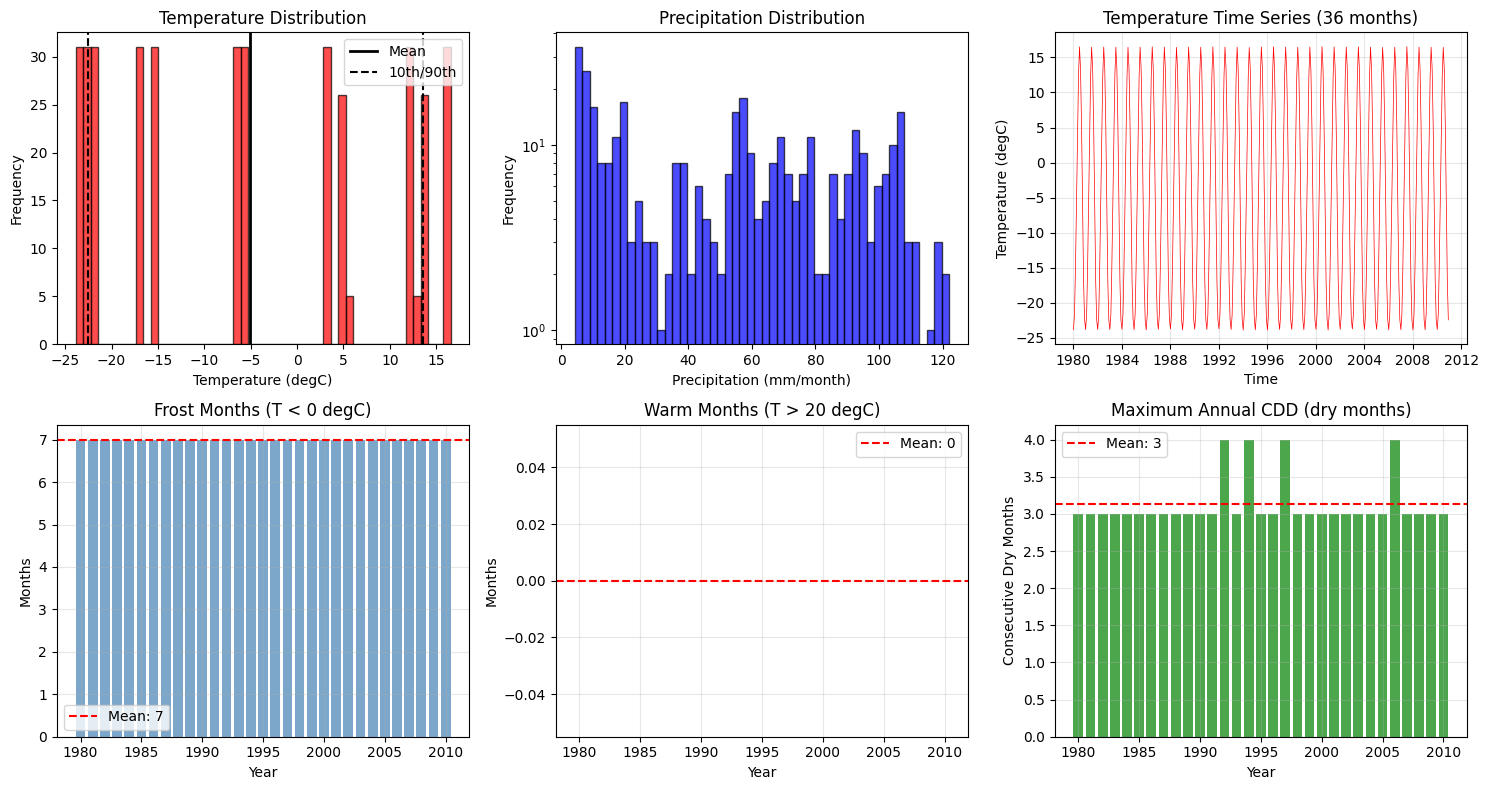

In [8]:
# Visualize results with histograms and time series
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Temperature histogram
temp_vals = np.asarray(ds_orig_reload.temperature.values, dtype=float).ravel()
temp_vals = temp_vals[np.isfinite(temp_vals)]
axes[0, 0].hist(temp_vals, bins=50, color='red', alpha=0.7, edgecolor='black')
axes[0, 0].axvline(ds_mean.temperature.values.ravel()[0], color='k', linestyle='-', linewidth=2, label='Mean')
axes[0, 0].axvline(ds_p10.temperature.values.ravel()[0], color='k', linestyle='--', label='10th/90th')
axes[0, 0].axvline(ds_p90.temperature.values.ravel()[0], color='k', linestyle='--')
axes[0, 0].set_xlabel('Temperature (degC)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Temperature Distribution')
axes[0, 0].legend()

# Precipitation histogram
precip_vals = np.asarray(ds_orig_reload.precipitation.values, dtype=float).ravel()
precip_vals = precip_vals[np.isfinite(precip_vals)]
axes[0, 1].hist(precip_vals, bins=50, color='blue', alpha=0.7, edgecolor='black')
axes[0, 1].set_xlabel('Precipitation (mm/month)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Precipitation Distribution')
axes[0, 1].set_yscale('log')

# Temperature time series (subset: 3 years)
subset_end = 365 * 3  # 3 years
axes[0, 2].plot(ds_orig_reload.time[:subset_end],
                ds_orig_reload.temperature[:subset_end], linewidth=0.5, color='red')
axes[0, 2].set_xlabel('Time')
axes[0, 2].set_ylabel('Temperature (degC)')
axes[0, 2].set_title('Temperature Time Series (36 months)')
axes[0, 2].grid(alpha=0.3)

# Frost days time series
axes[1, 0].bar(frost_days_year.year.values, frost_days_year.values, color='steelblue', alpha=0.7)
axes[1, 0].axhline(y=frost_days_year.mean().values, color='red', linestyle='--', label=f'Mean: {frost_days_year.mean().values:.0f}')
axes[1, 0].set_xlabel('Year')
axes[1, 0].set_ylabel('Months')
axes[1, 0].set_title('Frost Months (T < 0 degC)')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Tropical nights time series
axes[1, 1].bar(tropical_nights_year.year.values, tropical_nights_year.values, color='coral', alpha=0.7)
axes[1, 1].axhline(y=tropical_nights_year.mean().values, color='red', linestyle='--',
                   label=f'Mean: {tropical_nights_year.mean().values:.0f}')
axes[1, 1].set_xlabel('Year')
axes[1, 1].set_ylabel('Months')
axes[1, 1].set_title('Warm Months (T > 20 degC)')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

# CDD time series
axes[1, 2].bar(yearly_cdd.year.values, yearly_cdd.values, color='green', alpha=0.7)
axes[1, 2].axhline(y=yearly_cdd.mean().values, color='red', linestyle='--',
                   label=f'Mean: {yearly_cdd.mean().values:.0f}')
axes[1, 2].set_xlabel('Year')
axes[1, 2].set_ylabel('Consecutive Dry Months')
axes[1, 2].set_title('Maximum Annual CDD (dry months)')
axes[1, 2].legend()
axes[1, 2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Exercises

1. Compute growing season length (days with T > 5 degC for at least 6 consecutive days) using `cdo ecacf,gsl`
2. Compute heat wave duration index using `cdo ecacf,hwdi`
3. Compute the 95th percentile of precipitation and count days exceeding it
4. Compute the simple daily intensity index (SDII): mean precipitation on wet days (>= 1mm)
5. Create a combined plot showing the annual cycle of temperature with ±1 standard deviation shaded

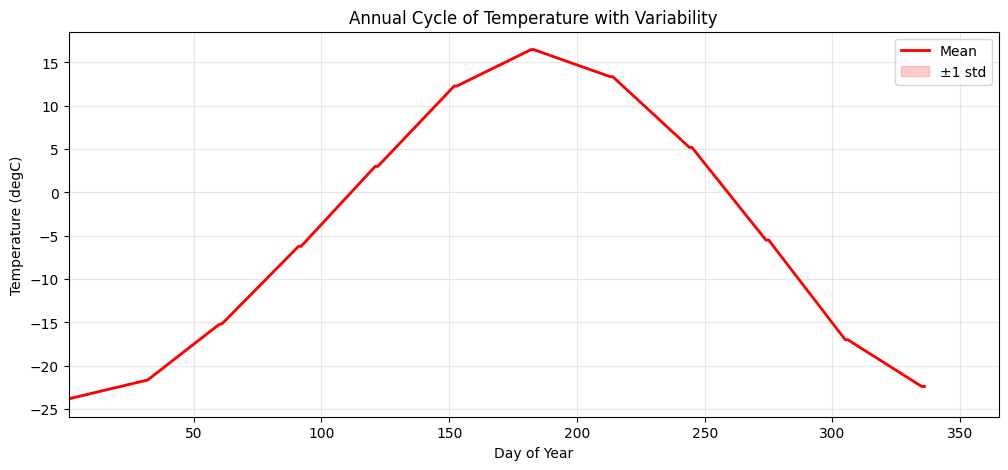

In [9]:
# Exercise 5: Annual cycle with variability
ds_orig_reload = xr.open_dataset(ts_file)

# Group by day of year
annual_cycle = ds_orig_reload.temperature.groupby('time.dayofyear').mean()
annual_std = ds_orig_reload.temperature.groupby('time.dayofyear').std()

plt.figure(figsize=(12, 5))
plt.plot(annual_cycle.dayofyear, annual_cycle, color='red', linewidth=2, label='Mean')
plt.fill_between(annual_cycle.dayofyear,
                 annual_cycle - annual_std,
                 annual_cycle + annual_std,
                 color='red', alpha=0.2, label='±1 std')
plt.xlabel('Day of Year')
plt.ylabel('Temperature (degC)')
plt.title('Annual Cycle of Temperature with Variability')
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(1, 365)
plt.show()